In [16]:
import numpy as np

In [17]:
true_w = 2
true_b = 1
N = 100

np.random.seed(42)
x = np.random.rand(N, 1)
epsilon = (.1 * np.random.randn(N,1))
y = true_b + true_w * x + epsilon

print(x.shape, y.shape)
print("x=", x[:10], "...")
print("y=", y[:10], "...")

(100, 1) (100, 1)
x= [[0.37454012]
 [0.95071431]
 [0.73199394]
 [0.59865848]
 [0.15601864]
 [0.15599452]
 [0.05808361]
 [0.86617615]
 [0.60111501]
 [0.70807258]] ...
y= [[1.75778494]
 [2.87152788]
 [2.47316396]
 [1.99856008]
 [1.29007009]
 [1.3477003 ]
 [1.26395663]
 [2.68052527]
 [2.12138066]
 [2.36596945]] ...


In [18]:
idx = np.arange(N)
np.random.shuffle(idx)

train_idx = idx[:int(N*.8)]
test_idx = idx[int(N*.8):]

print("indexes: ", train_idx[:5], test_idx[:5])

x_train, y_train = x[train_idx], y[train_idx]
x_test, y_test = x[test_idx], y[test_idx]

indexes:  [76 83 80 98  2] [36  5 45 99 43]


In [19]:
# training

np.random.seed(42)
b = np.random.randn(1)
w = np.random.randn(1)

print(b, w)

[0.49671415] [-0.1382643]


In [20]:
yhat = b + w * x_train

err = (y_train - yhat)
loss = (err ** 2).mean()

print(loss)

2.7421577700550976


In [21]:
b_grad = 2 * err.mean()
w_grad = 2 * (x_train * err).mean()

print(b_grad, w_grad)

3.044811379650508 1.8337537171510832


In [22]:
lr = 0.1
print(b, w)

b -= lr * b_grad
w -= lr * w_grad

print(b,w)

[0.49671415] [-0.1382643]
[0.19223302] [-0.32163967]


In [31]:
# training loop
np.random.seed(42)
b = np.random.randn(1)
w = np.random.randn(1)

print(b,w)

lr = 0.1
epochs = 100
losses = []
errs = []

for _ in range(epochs):
    yhat = b + w * x_train

    err = (yhat - y_train)
    loss = (err ** 2).mean()

    losses.append(int(loss))

    b_grad = 2 * err.mean()
    w_grad = 2 * (x_train * err).mean()

    b -= lr * b_grad
    w -= lr * w_grad


print(losses[:5])
print(b,w)

[0.49671415] [-0.1382643]
[2, 1, 1, 0, 0]
[1.18607329] [1.65093557]


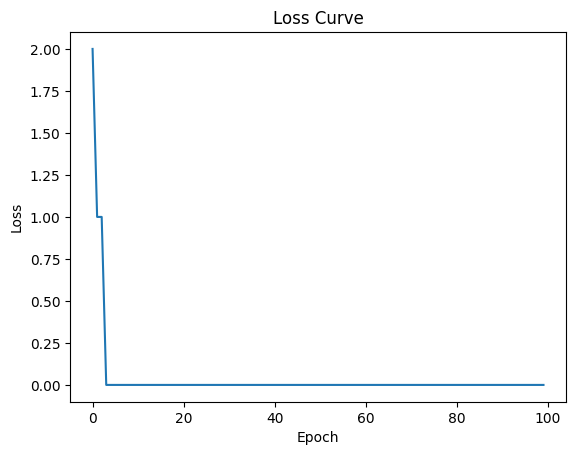

In [32]:
import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss Curve")
plt.show()